# Task 1: FER2013 baseline — classifiers × features

Compares **3 classifiers** (Logistic Regression, SVM, Random Forest) on **3 feature types** (HOG, facial landmarks, PCA) using the provided FER2013 splits.

**Protocol (as required by the assignment)**
- `training` split → fit models
- `validation` (PublicTest) → model selection and hyperparameter tuning
- `test` (PrivateTest) → touched **only once**, in the last section, for the selected models

**Run `z_load_split_fer2013.ipynb` first** so `data/fer/fer2013_{train,validation,test}.csv` exist.

## 0. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from skimage.feature import hog
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
ROOT      = os.getcwd()
FER_DIR   = os.path.join(ROOT, "data", "fer")
FEAT_DIR  = os.path.join(FER_DIR, "features")          # cached feature matrices
MODEL_DIR = os.path.join(ROOT, "models")               # trained .pkl files (deliverable)
FIG_DIR   = os.path.join(ROOT, "figures")              # figures for the report appendix
LANDMARK_MODEL = os.path.join(ROOT, "models", "faceAndLandmarkModels",
                              "shape_predictor_68_face_landmarks_GTX.dat")
for d in (FEAT_DIR, MODEL_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

EMOTIONS = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]  # FER labels 0..6

# Task 1 = plain baseline (no class balancing). Switch to "balanced" in Task 5 to study its effect.
CLASS_WEIGHT = None

# Feature hyperparameters (keep these in the report)
HOG_PARAMS     = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
PCA_COMPONENTS = 100

## 1. Load data (train + validation only)
The test split is deliberately *not* loaded here.

train: (28709, 48, 48)  validation: (3589, 48, 48)
 emotion  train  validation
   Angry   3995         467
 Disgust    436          56
    Fear   4097         496
   Happy   7215         895
     Sad   4830         653
Surprise   3171         415
 Neutral   4965         607


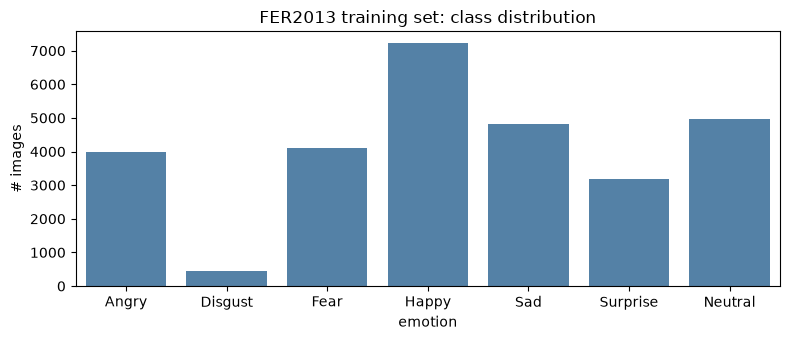

balanced class weights: {'Angry': np.float64(1.03), 'Disgust': np.float64(9.41), 'Fear': np.float64(1.0), 'Happy': np.float64(0.57), 'Sad': np.float64(0.85), 'Surprise': np.float64(1.29), 'Neutral': np.float64(0.83)}


In [2]:
def load_split(name):
    df = pd.read_csv(os.path.join(FER_DIR, f"fer2013_{name}.csv"))
    imgs = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in df["pixels"]])
    return imgs, df["emotion"].values

img_train, y_train = load_split("train")
img_val,   y_val   = load_split("validation")
print("train:", img_train.shape, " validation:", img_val.shape)

counts = pd.DataFrame({
    "emotion": EMOTIONS,
    "train": np.bincount(y_train, minlength=7),
    "validation": np.bincount(y_val, minlength=7),
})
print(counts.to_string(index=False))

plt.figure(figsize=(8, 3.5))
sns.barplot(data=counts, x="emotion", y="train", color="steelblue")
plt.title("FER2013 training set: class distribution"); plt.ylabel("# images")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "fer_class_distribution.png"), dpi=150); plt.show()

cw = compute_class_weight("balanced", classes=np.arange(7), y=y_train)
print("balanced class weights:", dict(zip(EMOTIONS, cw.round(2))))

## 2. Feature extraction

| Feature | Description | Dim |
|---|---|---|
| **HOG** | histogram of oriented gradients on the 48×48 image | 900 |
| **Landmarks** | dlib 68 landmarks, normalised (centred, scaled to [-1,1]) | 136 |
| **PCA** | raw pixels in [0,1] → PCA (fitted **inside the pipeline on training data only**, so no leakage) | 100 |

Features are cached to `data/fer/features/`. **Delete the cache if you change the feature parameters.**

In [3]:
def extract_hog(images):
    return np.stack([hog(im / 255.0, block_norm="L2-Hys", **HOG_PARAMS) for im in images]).astype(np.float32)

def extract_pixels(images):
    # raw pixels in [0,1]; PCA is applied later inside the sklearn Pipeline
    return images.reshape(len(images), -1).astype(np.float32) / 255.0

# --- landmarks (same normalisation as the provided baseline) -------------------------------
_landm_det = None
def extract_landmarks(images):
    global _landm_det
    import dlib
    if _landm_det is None:
        if not os.path.exists(LANDMARK_MODEL):
            raise FileNotFoundError(f"dlib model not found: {LANDMARK_MODEL}")
        _landm_det = dlib.shape_predictor(LANDMARK_MODEL)
    # The whole 48x48 image is treated as the face box. The demo script uses the same box (0,0,47,47),
    # so training and real-time inference see identically-computed features.
    rect = dlib.rectangle(left=0, top=0, right=47, bottom=47)
    x1, y1, x2, y2 = rect.left(), rect.top(), rect.right(), rect.bottom()
    out = []
    for img in images:
        shape = _landm_det(img.astype(np.uint8), rect)
        pts = np.array([[(p.x - 0.5 * (x2 - x1)) / (x2 - x1),
                         (p.y - 0.5 * (y2 - y1)) / (y2 - y1)] for p in shape.parts()], dtype=np.float32)
        pts -= pts.mean(axis=0, keepdims=True)
        pts /= np.max(np.abs(pts), axis=0, keepdims=True)
        out.append(pts.flatten())
    return np.stack(out)

def cached_features(name, fn, images, split):
    path = os.path.join(FEAT_DIR, f"{name}_{split}.npy")
    if os.path.exists(path):
        return np.load(path)
    t = time.time(); X = fn(images); np.save(path, X)
    print(f"  {name}/{split}: {X.shape} in {time.time()-t:.0f}s")
    return X

FEATURE_FNS = {"HOG": ("hog", extract_hog),
               "Landmarks": ("landmarks", extract_landmarks),
               "PCA": ("pixels", extract_pixels)}

FEATURES = {}
for feat, (cache_name, fn) in FEATURE_FNS.items():
    FEATURES[feat] = (cached_features(cache_name, fn, img_train, "train"),
                      cached_features(cache_name, fn, img_val, "validation"))
    print(feat, "train", FEATURES[feat][0].shape, "val", FEATURES[feat][1].shape)

HOG train (28709, 900) val (3589, 900)
Landmarks train (28709, 136) val (3589, 136)
PCA train (28709, 2304) val (3589, 2304)


## 3. Models and metrics

In [4]:
def make_model(clf_name, feat_name, **params):
    """Build a sklearn Pipeline. `params` override the classifier's defaults (used for tuning)."""
    steps = []
    if feat_name == "PCA":
        steps.append(("pca", PCA(n_components=PCA_COMPONENTS, whiten=True, random_state=RANDOM_STATE)))
    elif clf_name in ("LogReg", "SVM"):
        steps.append(("scaler", StandardScaler()))       # RF doesn't need scaling

    if clf_name == "LogReg":
        kw = dict(C=1.0, max_iter=2000, class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
        kw.update(params); clf = LogisticRegression(**kw)
    elif clf_name == "SVM":
        kw = dict(kernel="rbf", C=1.0, gamma="scale", cache_size=1000,
                  class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
        kw.update(params); clf = SVC(**kw)
    elif clf_name == "RF":
        kw = dict(n_estimators=300, max_depth=None, max_features="sqrt", n_jobs=-1,
                  class_weight=CLASS_WEIGHT, random_state=RANDOM_STATE)
        kw.update(params); clf = RandomForestClassifier(**kw)
    else:
        raise ValueError(clf_name)
    steps.append(("clf", clf))
    return Pipeline(steps)

def scores(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred),
                balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
                macro_f1=f1_score(y_true, y_pred, average="macro"))

CLASSIFIERS = ["LogReg", "SVM", "RF"]

## 4. Experiment grid (fit on **train**, evaluate on **validation**)

⚠️ The RBF-SVM on 28k samples is the slow part (minutes per feature set, longest for HOG). Set `SVM_SUBSAMPLE` to e.g. `8000` for a quick first run, then back to `None`.

In [5]:
SVM_SUBSAMPLE = None     # e.g. 8000 for a quick dry run; None = use all training data

rows, fitted, val_pred = [], {}, {}
rng = np.random.RandomState(RANDOM_STATE)
for feat in FEATURES:
    Xtr, Xva = FEATURES[feat]
    for clf in CLASSIFIERS:
        idx = np.arange(len(Xtr))
        if clf == "SVM" and SVM_SUBSAMPLE:
            idx = rng.choice(len(Xtr), SVM_SUBSAMPLE, replace=False)
        model = make_model(clf, feat)
        t = time.time(); model.fit(Xtr[idx], y_train[idx]); fit_s = time.time() - t
        y_pred = model.predict(Xva)
        fitted[(feat, clf)], val_pred[(feat, clf)] = model, y_pred
        rows.append(dict(features=feat, classifier=clf, **scores(y_val, y_pred), fit_seconds=round(fit_s, 1)))
        print(f"{feat:10s} {clf:7s} acc={rows[-1]['accuracy']:.3f} bal={rows[-1]['balanced_accuracy']:.3f} "
              f"F1={rows[-1]['macro_f1']:.3f}  ({fit_s:.0f}s)")

results = pd.DataFrame(rows)
results.to_csv(os.path.join(FIG_DIR, "task1_validation_results.csv"), index=False)
results.round(3)

HOG        LogReg  acc=0.435 bal=0.397 F1=0.396  (63s)
HOG        SVM     acc=0.542 bal=0.482 F1=0.505  (416s)
HOG        RF      acc=0.480 bal=0.412 F1=0.438  (14s)
Landmarks  LogReg  acc=0.429 bal=0.359 F1=0.353  (24s)
Landmarks  SVM     acc=0.452 bal=0.362 F1=0.352  (59s)
Landmarks  RF      acc=0.466 bal=0.411 F1=0.429  (5s)
PCA        LogReg  acc=0.382 bal=0.299 F1=0.287  (4s)
PCA        SVM     acc=0.477 bal=0.410 F1=0.430  (54s)
PCA        RF      acc=0.455 bal=0.396 F1=0.424  (10s)


,features,classifier,accuracy,balanced_accuracy,macro_f1,fit_seconds
0,HOG,LogReg,0.435,0.397,0.396,63.2
1,HOG,SVM,0.542,0.482,0.505,415.6
2,HOG,RF,0.480,0.412,0.438,14.0
3,Landmarks,LogReg,0.429,0.359,0.353,23.7
4,Landmarks,SVM,0.452,0.362,0.352,58.6
5,Landmarks,RF,0.466,0.411,0.429,5.4
6,PCA,LogReg,0.382,0.299,0.287,4.2
7,PCA,SVM,0.477,0.410,0.430,53.6
8,PCA,RF,0.455,0.396,0.424,10.2


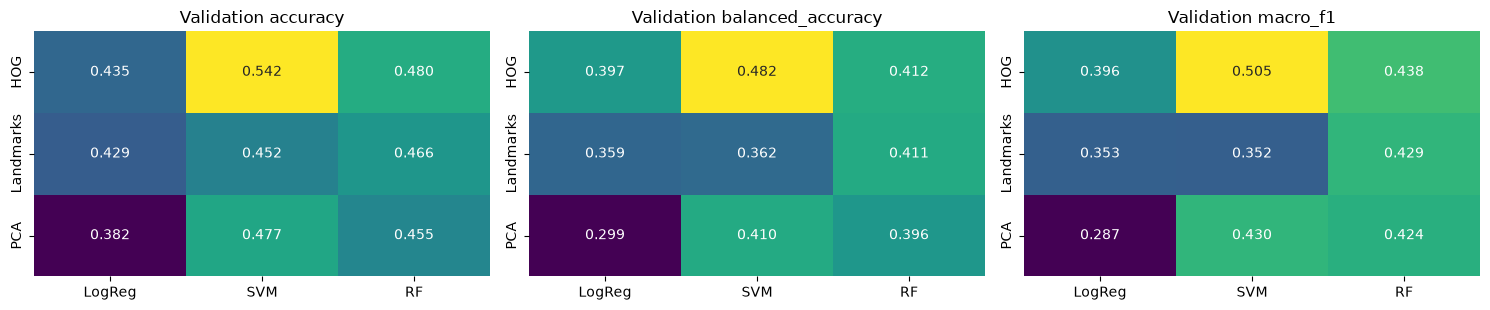

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, metric in zip(axes, ["accuracy", "balanced_accuracy", "macro_f1"]):
    piv = results.pivot(index="features", columns="classifier", values=metric)[CLASSIFIERS]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(f"Validation {metric}"); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_metric_heatmaps.png"), dpi=150); plt.show()

## 5. Confusion matrices for all 9 models (appendix figure)
Row-normalised (each row = true class, sums to 1).

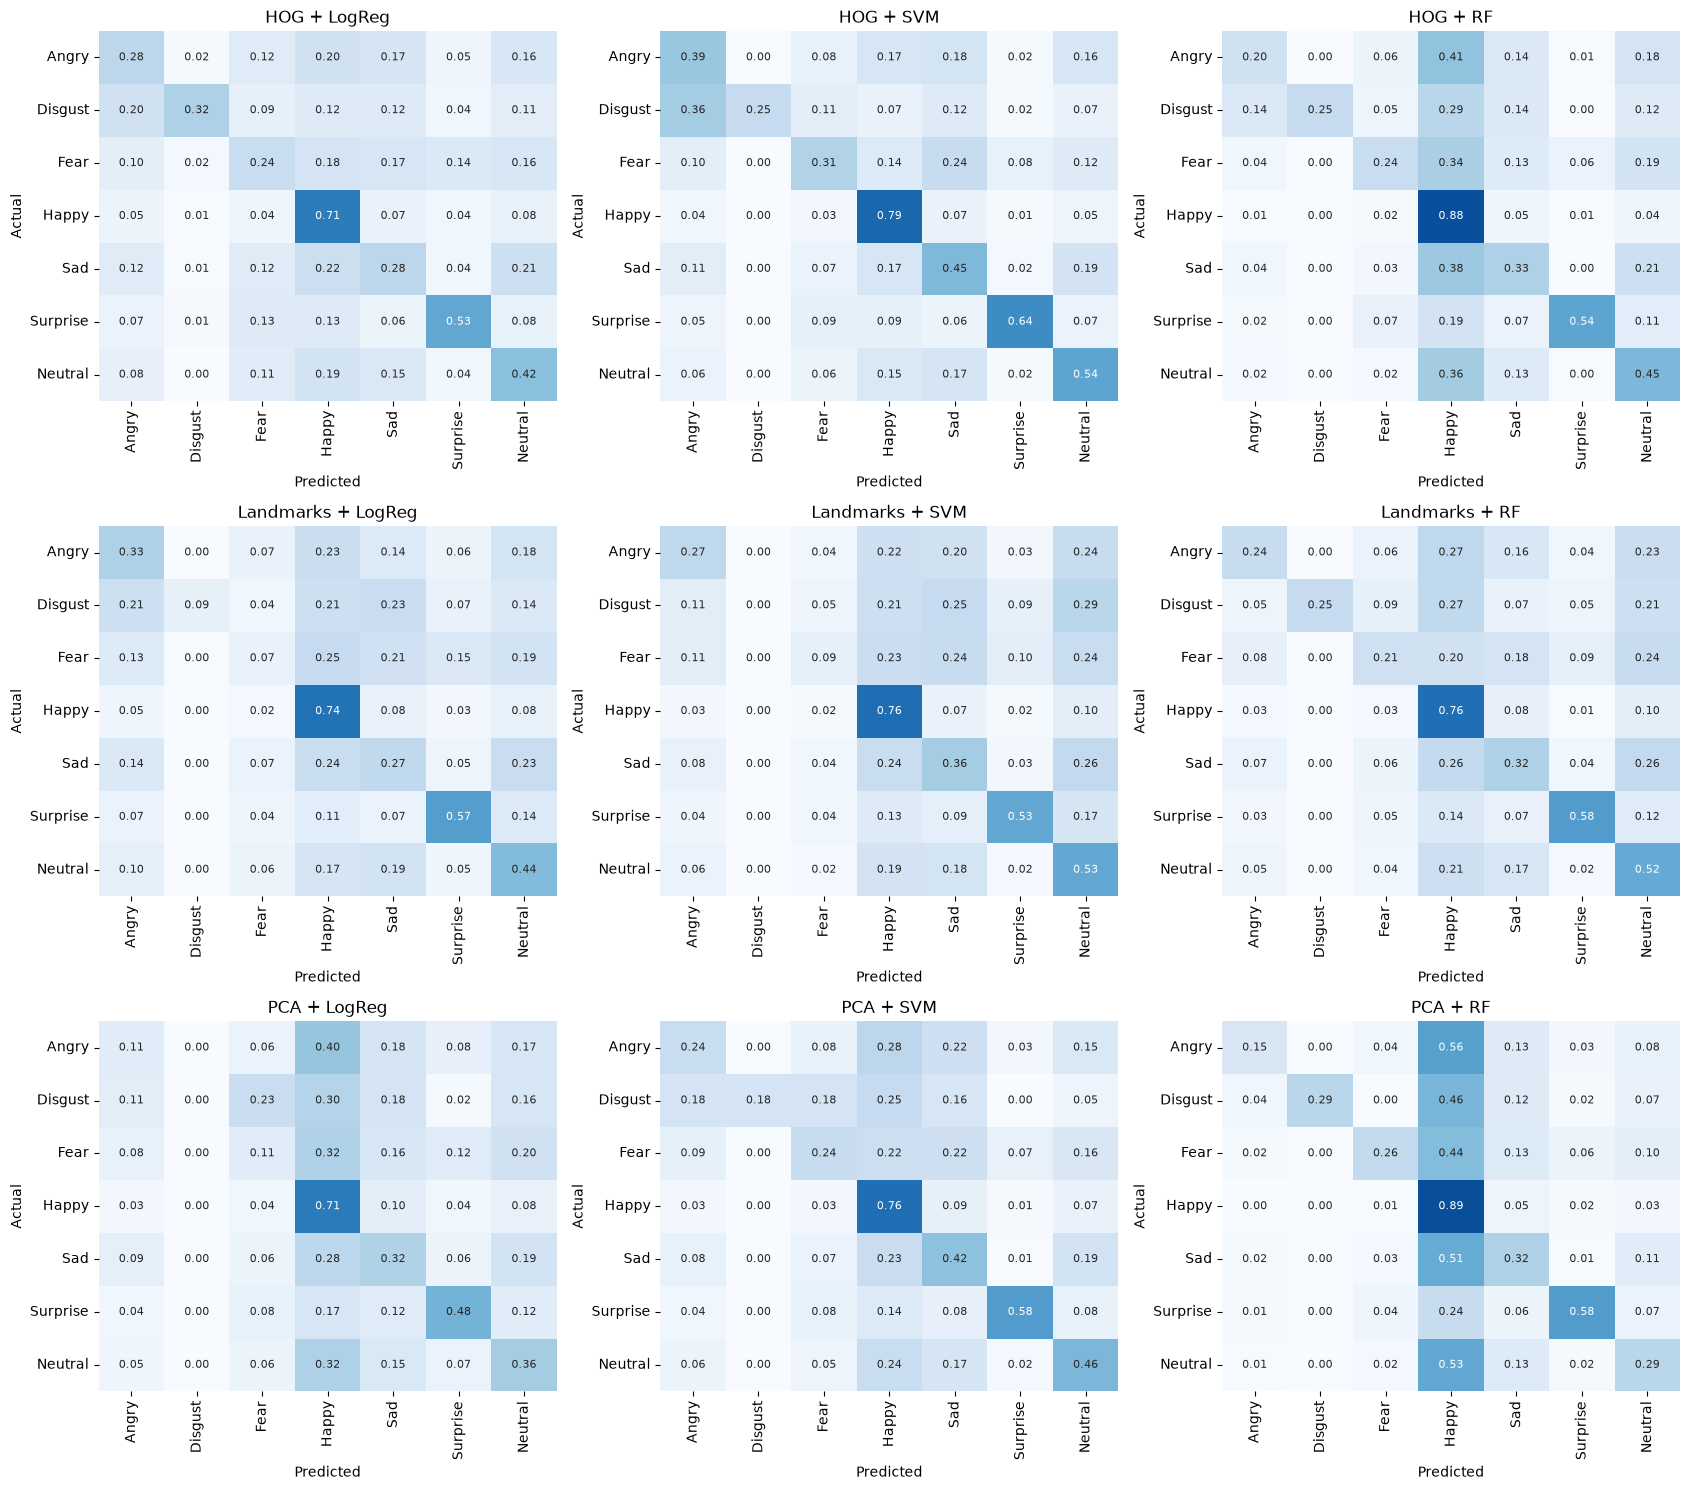

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(17, 15))
for i, feat in enumerate(FEATURES):
    for j, clf in enumerate(CLASSIFIERS):
        cm = confusion_matrix(y_val, val_pred[(feat, clf)], labels=range(7), normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=axes[i, j], annot_kws={"size": 8})
        axes[i, j].set_title(f"{feat} + {clf}"); axes[i, j].set_xlabel("Predicted"); axes[i, j].set_ylabel("Actual")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_confusion_matrices_val.png"), dpi=150); plt.show()

## 6. Which emotions are hardest? (per-class F1 on validation)

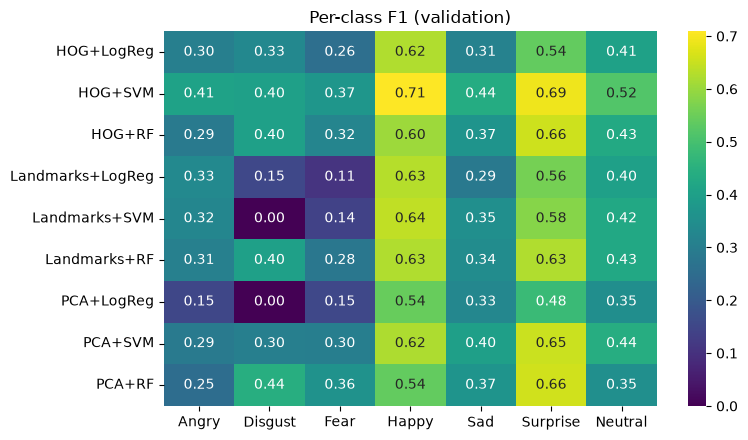

Mean F1 per emotion across all 9 models (low = hard):
Fear        0.255
Disgust     0.270
Angry       0.296
Sad         0.355
Neutral     0.415
Surprise    0.605
Happy       0.615


In [8]:
per_class = pd.DataFrame(
    {f"{f}+{c}": f1_score(y_val, val_pred[(f, c)], average=None, labels=range(7))
     for f in FEATURES for c in CLASSIFIERS}, index=EMOTIONS).T

plt.figure(figsize=(8, 4.5))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="viridis")
plt.title("Per-class F1 (validation)"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "task1_per_class_f1.png"), dpi=150); plt.show()

print("Mean F1 per emotion across all 9 models (low = hard):")
print(per_class.mean().sort_values().round(3).to_string())

## 7. Select the best configuration (by validation macro-F1)

In [9]:
best_row = results.sort_values("macro_f1", ascending=False).iloc[0]
BEST_FEAT, BEST_CLF = best_row["features"], best_row["classifier"]
print("Best on validation:", BEST_FEAT, "+", BEST_CLF)
print(results.sort_values("macro_f1", ascending=False).round(3).to_string(index=False))

print()
print(classification_report(y_val, val_pred[(BEST_FEAT, BEST_CLF)], target_names=EMOTIONS, digits=3))

# most frequent confusions
cm = confusion_matrix(y_val, val_pred[(BEST_FEAT, BEST_CLF)], labels=range(7))
off = [(EMOTIONS[i], EMOTIONS[j], cm[i, j], cm[i, j] / cm[i].sum()) for i in range(7) for j in range(7) if i != j]
print("Top confusions (true → predicted):")
for t, p, n, frac in sorted(off, key=lambda r: -r[2])[:6]:
    print(f"  {t:9s} → {p:9s}  {n:4d}  ({frac:.0%} of all {t})")

Best on validation: HOG + SVM
 features classifier  accuracy  balanced_accuracy  macro_f1  fit_seconds
      HOG        SVM     0.542              0.482     0.505        415.6
      HOG         RF     0.480              0.412     0.438         14.0
      PCA        SVM     0.477              0.410     0.430         53.6
Landmarks         RF     0.466              0.411     0.429          5.4
      PCA         RF     0.455              0.396     0.424         10.2
      HOG     LogReg     0.435              0.397     0.396         63.2
Landmarks     LogReg     0.429              0.359     0.353         23.7
Landmarks        SVM     0.452              0.362     0.352         58.6
      PCA     LogReg     0.382              0.299     0.287          4.2

              precision    recall  f1-score   support

       Angry      0.433     0.388     0.409       467
     Disgust      1.000     0.250     0.400        56
        Fear      0.453     0.315     0.371       496
       Happy      0.64

## 8. Evidence for the report: error analysis on validation (best model)
Lighting/contrast, hard examples and possibly mislabelled images.

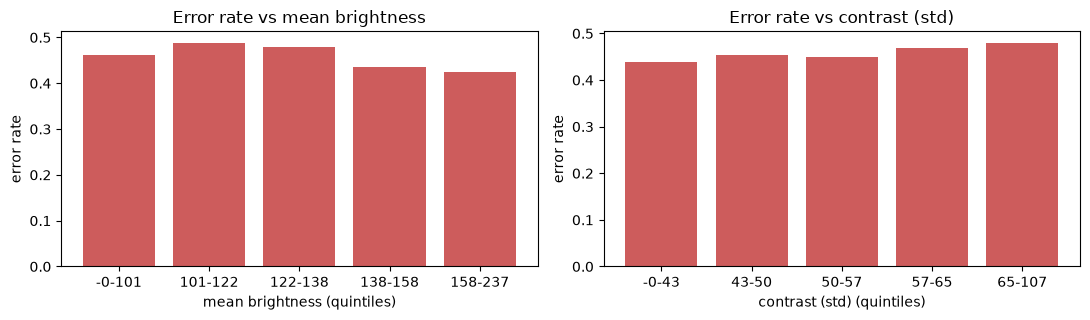

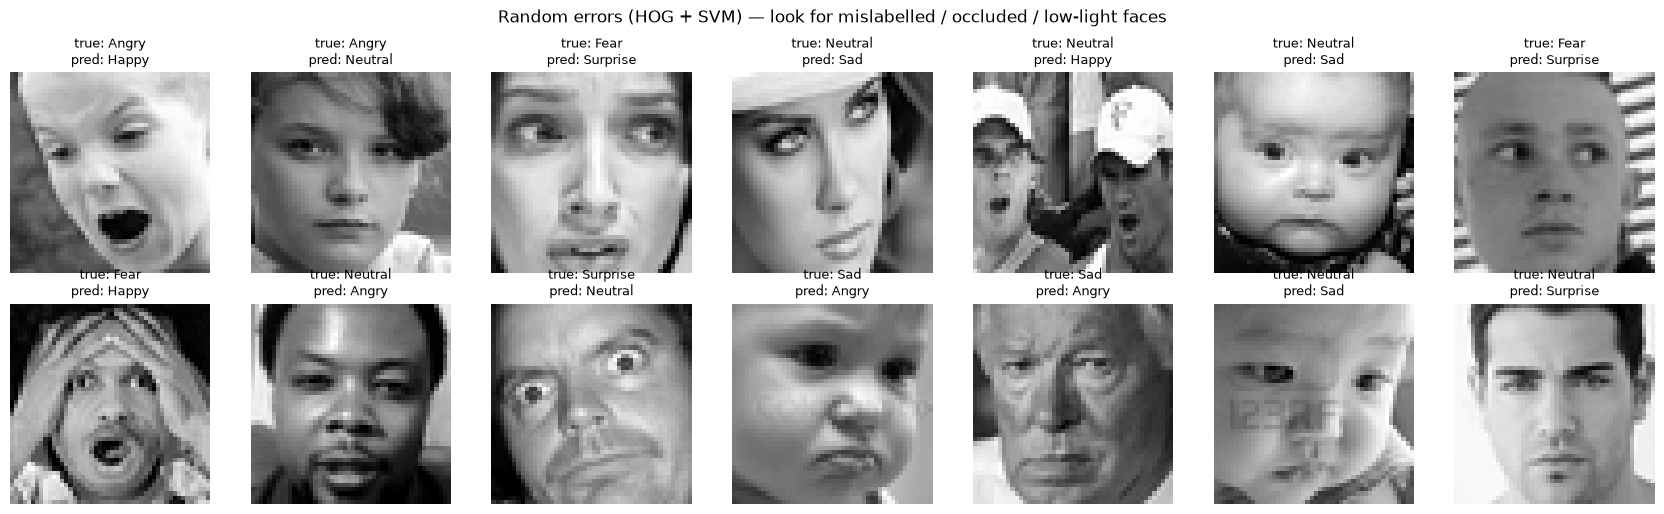

In [10]:
best_model = fitted[(BEST_FEAT, BEST_CLF)]
y_pred_b = val_pred[(BEST_FEAT, BEST_CLF)]
wrong = y_pred_b != y_val

# (a) error rate vs image brightness / contrast
brightness = img_val.reshape(len(img_val), -1).mean(axis=1)
contrast   = img_val.reshape(len(img_val), -1).std(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
for ax, vals, name in zip(axes, [brightness, contrast], ["mean brightness", "contrast (std)"]):
    bins = pd.qcut(vals, 5, duplicates="drop")
    err = pd.Series(wrong).groupby(bins, observed=True).mean()
    ax.bar(range(len(err)), err.values, color="indianred")
    ax.set_xticks(range(len(err))); ax.set_xticklabels([f"{iv.left:.0f}-{iv.right:.0f}" for iv in err.index])
    ax.set_xlabel(name + " (quintiles)"); ax.set_ylabel("error rate"); ax.set_title(f"Error rate vs {name}")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_error_vs_lighting.png"), dpi=150); plt.show()

# (b) gallery: confidently wrong predictions (candidates for label noise / hard samples)
final_clf = best_model.steps[-1][1]
if hasattr(final_clf, "predict_proba"):
    proba = best_model.predict_proba(FEATURES[BEST_FEAT][1])
    conf = proba[np.arange(len(y_val)), y_pred_b]
    order = np.argsort(-(conf * wrong))            # most confident errors first
    title = "Most confident errors"
else:
    order = np.where(wrong)[0]; np.random.RandomState(0).shuffle(order); title = "Random errors"
show = order[:14]
fig, axes = plt.subplots(2, 7, figsize=(17, 5.2))
for ax, k in zip(axes.ravel(), show):
    ax.imshow(img_val[k], cmap="gray"); ax.axis("off")
    ax.set_title(f"true: {EMOTIONS[y_val[k]]}\npred: {EMOTIONS[y_pred_b[k]]}", fontsize=9)
plt.suptitle(f"{title} ({BEST_FEAT} + {BEST_CLF}) — look for mislabelled / occluded / low-light faces")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "task1_hard_examples.png"), dpi=150); plt.show()

## 9. Light hyperparameter tuning of the selected configuration (validation only)
Small grid on the best (features, classifier) pair. Extend the grids if time allows; always select by **validation** macro-F1.

In [11]:
from joblib import Parallel, delayed
N_JOBS = max(1, (os.cpu_count() or 2) - 1)

TUNE_SUBSAMPLE = 5000      # SVM only; the final refit in section 10 uses ALL training data
TUNE_GRID = {
    "LogReg": {"C": [0.1, 1, 10]},
    "SVM":    {"C": [1, 5, 10]},                       # gamma left at "scale"
    "RF":     {"max_depth": [None, 25], "min_samples_leaf": [1, 3]},
}

Xtr, Xva = FEATURES[BEST_FEAT]
if BEST_CLF == "SVM" and TUNE_SUBSAMPLE < len(Xtr):
    sel = np.random.RandomState(RANDOM_STATE).choice(len(Xtr), TUNE_SUBSAMPLE, replace=False)
    Xt, yt = Xtr[sel], y_train[sel]
else:
    Xt, yt = Xtr, y_train

def tune_one(params, clf, feat, Xt, yt, Xva, yva):
    extra = {"n_jobs": 1} if clf == "RF" else {}
    m = make_model(clf, feat, **params, **extra).fit(Xt, yt)
    return {**params, **scores(yva, m.predict(Xva))}

tune_params = list(ParameterGrid(TUNE_GRID[BEST_CLF]))
tune_rows = Parallel(n_jobs=N_JOBS, verbose=5)(
    delayed(tune_one)(p, BEST_CLF, BEST_FEAT, Xt, yt, Xva, y_val) for p in tune_params)

tune = pd.DataFrame(tune_rows).sort_values("macro_f1", ascending=False)
BEST_PARAMS = tune_params[int(np.argmax([r["macro_f1"] for r in tune_rows]))]
print("Best params:", BEST_PARAMS)
tune.round(3)

[Parallel(n_jobs=21)]: Using backend LokyBackend with 21 concurrent workers.


Best params: {'C': 5}


[Parallel(n_jobs=21)]: Done   3 out of   3 | elapsed:   28.0s finished


,C,accuracy,balanced_accuracy,macro_f1
1,5,0.463,0.391,0.402
2,10,0.463,0.391,0.402
0,1,0.463,0.376,0.381


## 10. FINAL evaluation on the held-out test split (PrivateTest)

⚠️ **Run this once**, after all selection decisions above are final. Add other models to `SELECTED` only if the report needs them
(each entry: `(features, classifier, params)`). Models are refit on the training split and saved to `models/`.

  hog/test: (3589, 900) in 1s
=== HOG + SVM (TEST) ===
              precision    recall  f1-score   support

       Angry      0.454     0.413     0.433       491
     Disgust      0.800     0.509     0.622        55
        Fear      0.486     0.436     0.460       528
       Happy      0.705     0.802     0.750       879
         Sad      0.420     0.453     0.436       594
    Surprise      0.774     0.692     0.731       416
     Neutral      0.544     0.540     0.542       626

    accuracy                          0.574      3589
   macro avg      0.598     0.549     0.568      3589
weighted avg      0.573     0.574     0.572      3589



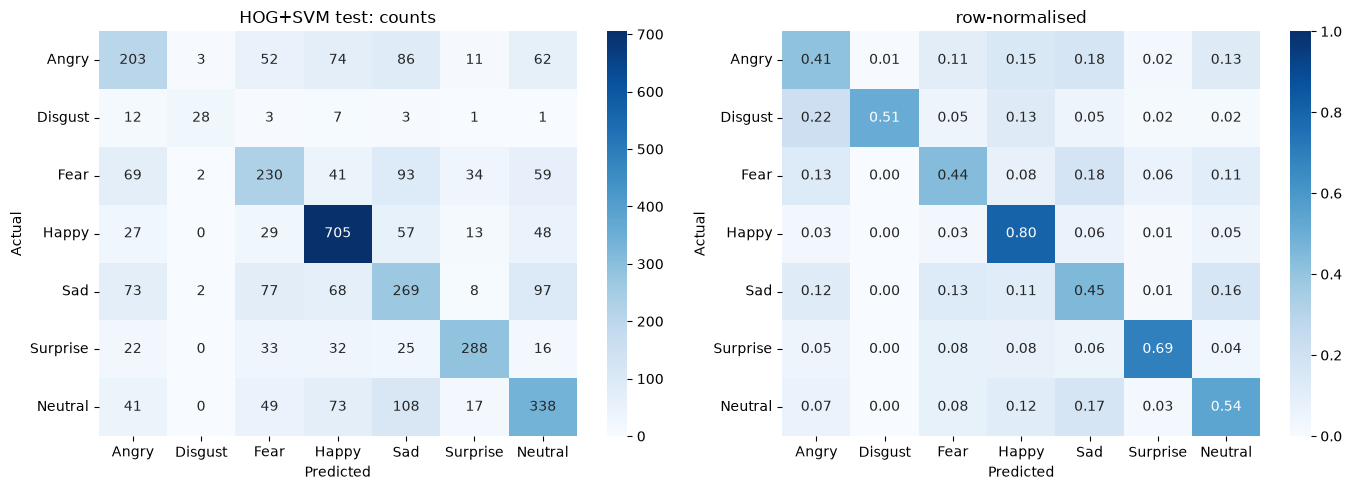

,features,classifier,params,accuracy,balanced_accuracy,macro_f1
0,HOG,SVM,{'C': 5},0.574,0.549,0.568


In [13]:
RUN_FINAL_TEST = True     # <-- set to True only when you are done choosing

SELECTED = [(BEST_FEAT, BEST_CLF, BEST_PARAMS)]

if RUN_FINAL_TEST:
    img_test, y_test = load_split("test")
    final_rows = []
    for feat, clf, params in SELECTED:
        fn = FEATURE_FNS[feat][1]
        Xte = cached_features(FEATURE_FNS[feat][0], fn, img_test, "test")
        Xtr = FEATURES[feat][0]
        model = make_model(clf, feat, **params).fit(Xtr, y_train)
        y_pred = model.predict(Xte)
        sc = scores(y_test, y_pred)
        final_rows.append(dict(features=feat, classifier=clf, params=str(params), **sc))

        print(f"=== {feat} + {clf} (TEST) ===")
        print(classification_report(y_test, y_pred, target_names=EMOTIONS, digits=3))
        cm = confusion_matrix(y_test, y_pred, labels=range(7))
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax[0])
        sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                    xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=ax[1])
        ax[0].set_title(f"{feat}+{clf} test: counts"); ax[1].set_title("row-normalised")
        for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("Actual")
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"task1_confusion_test_{feat}_{clf}.png"), dpi=150); plt.show()

        joblib.dump(model, os.path.join(MODEL_DIR, f"fer_{feat.lower()}_{clf.lower()}.pkl"))
    final = pd.DataFrame(final_rows); final.to_csv(os.path.join(FIG_DIR, "task1_test_results.csv"), index=False)
    display(final.round(3))
else:
    print("Final test evaluation skipped (RUN_FINAL_TEST = False).")

## Sanity checks to assess data leakage and label noise

In [ ]:
# Check for duplicates between train and test (FER2013 has some)
import hashlib
from collections import defaultdict
hh = lambda im: hashlib.md5(im.tobytes()).hexdigest()

train_labels = defaultdict(set)
for im, y in zip(img_train, y_train):
    train_labels[hh(im)].add(y)

test_hash = [hh(im) for im in img_test]
dup   = np.array([h in train_labels for h in test_hash])
agree = np.array([dup[i] and (y_test[i] in train_labels[test_hash[i]]) for i in range(len(y_test))])

print(f"test images also in train: {dup.sum()} ({dup.mean():.1%}); "
      f"of those, same label as the train copy: {agree[dup].mean():.1%}")
for name, m in [("all test", np.ones_like(dup)), ("not in train", ~dup), ("duplicated", dup)]:
    print(f"{name:13s} n={m.sum():5d}", {k: round(v, 3) for k, v in scores(y_test[m], y_pred[m]).items()})

test images also in train: 288 (8.0%); of those, same label as the train copy: 96.9%
all test      n= 3589 {'accuracy': 0.574, 'balanced_accuracy': 0.549, 'macro_f1': 0.568}
not in train  n= 3301 {'accuracy': 0.541, 'balanced_accuracy': 0.486, 'macro_f1': 0.504}
duplicated    n=  288 {'accuracy': 0.958, 'balanced_accuracy': 0.951, 'macro_f1': 0.95}


In [ ]:
# The table below shows the effect of removing duplicates from the validation set. 
# The "drop" column is the difference between the F1 score on all validation images 
# and the F1 score on only the non-duplicate images. A large drop indicates that 
# the model is overfitting to duplicates in the training set.

train_hashes = set(train_labels)
clean = ~np.array([hh(im) in train_hashes for im in img_val])
tab = pd.DataFrame([dict(features=f, classifier=c,
        f1_all=f1_score(y_val, yp, average="macro"),
        f1_dedup=f1_score(y_val[clean], yp[clean], average="macro"))
        for (f, c), yp in val_pred.items()])
tab["drop"] = tab.f1_all - tab.f1_dedup
tab.sort_values("f1_dedup", ascending=False).round(3)

,features,classifier,f1_all,f1_dedup,drop
1,HOG,SVM,0.505,0.438,0.067
0,HOG,LogReg,0.396,0.368,0.028
7,PCA,SVM,0.430,0.363,0.067
3,Landmarks,LogReg,0.353,0.344,0.009
4,Landmarks,SVM,0.352,0.341,0.010
2,HOG,RF,0.438,0.328,0.110
5,Landmarks,RF,0.429,0.322,0.107
8,PCA,RF,0.424,0.320,0.104
6,PCA,LogReg,0.287,0.277,0.010


In [17]:
# Access the results of the final test evaluation (if RUN_FINAL_TEST = True) 
# and the class counts in the training and validation sets. 
# Also, display the mean F1 score per emotion across the 9 models, 
# the top confusions for the selected model, and the tuning results.

print("== §4 results (accuracy, balanced acc, macro-F1, train F1, fit seconds) ==")
print(results.round(3).to_string(index=False))

print("\n== §1 class counts ==")
print(counts.to_string(index=False))

print("\n== §6 mean F1 per emotion across the 9 models (low = hard) ==")
print(per_class.mean().sort_values().round(3).to_string())

print("\n== §7 top confusions for the selected model (true -> predicted) ==")
for t, p, n, frac in sorted(off, key=lambda r: -r[2])[:6]:
    print(f"  {t:9s} -> {p:9s} {n:4d} ({frac:.0%} of all {t})")

print("\n== §9 tuning results ==")
print(tune.round(3).to_string(index=False))

== §4 results (accuracy, balanced acc, macro-F1, train F1, fit seconds) ==
 features classifier  accuracy  balanced_accuracy  macro_f1  fit_seconds
      HOG     LogReg     0.435              0.397     0.396         63.2
      HOG        SVM     0.542              0.482     0.505        415.6
      HOG         RF     0.480              0.412     0.438         14.0
Landmarks     LogReg     0.429              0.359     0.353         23.7
Landmarks        SVM     0.452              0.362     0.352         58.6
Landmarks         RF     0.466              0.411     0.429          5.4
      PCA     LogReg     0.382              0.299     0.287          4.2
      PCA        SVM     0.477              0.410     0.430         53.6
      PCA         RF     0.455              0.396     0.424         10.2

== §1 class counts ==
 emotion  train  validation
   Angry   3995         467
 Disgust    436          56
    Fear   4097         496
   Happy   7215         895
     Sad   4830         653
Surp

In [18]:
print(len(Xt) if "Xt" in globals() else len(idx))

5000


## 11. Notes for the report -DELETE BEFORE SUBMISSION

### Main results
- Protocol: fit on train, select on validation (PublicTest), evaluate on test (PrivateTest) once.
- Selected configuration: **HOG + RBF-SVM, C=5**. Tuning was done on a subset of 5000 images; the final model was refit on all 28,709 training images.
- **Test result:** accuracy 0.574, balanced accuracy 0.549, macro-F1 0.568.
- Validation macro-F1, all nine configurations (full training data, default hyperparameters):

| features | LogReg | SVM | RF |
|---|---|---|---|
| HOG | 0.396 | **0.505** | 0.438 |
| Landmarks | 0.353 | 0.352 | 0.429 |
| PCA | 0.287 | 0.430 | 0.424 |

== results (accuracy, balanced acc, macro-F1, train F1, fit seconds) ==
 features classifier  accuracy  balanced_accuracy  macro_f1  fit_seconds
      HOG     LogReg     0.435              0.397     0.396         63.2
      HOG        SVM     0.542              0.482     0.505        415.6
      HOG         RF     0.480              0.412     0.438         14.0
Landmarks     LogReg     0.429              0.359     0.353         23.7
Landmarks        SVM     0.452              0.362     0.352         58.6
Landmarks         RF     0.466              0.411     0.429          5.4
      PCA     LogReg     0.382              0.299     0.287          4.2
      PCA        SVM     0.477              0.410     0.430         53.6
      PCA         RF     0.455              0.396     0.424         10.2

### Which classifier performs best, and why
- **The RBF-SVM on HOG is clearly best** (0.505 vs 0.438 for the next model). The margin is roughly 0.07, well above run-to-run noise (single seed, ~3.6k validation images).
- **The ranking depends on the features.** The SVM wins on HOG and PCA, but on landmarks Random Forest looks best (0.429 vs 0.35). **That advantage disappears after de-duplication** (see the duplicates section): on landmarks, LogReg 0.344 ≈ SVM 0.341 > RF 0.322.
- **Random Forest overfits.** It lost about 0.10–0.11 macro-F1 on every feature type once duplicates were removed. Fully grown trees can memorise training images. .
- **Logistic Regression** is the lowest-capacity model. It is nearly as good as the SVM on landmarks, and is the cheapest to run. **▶ fill in:** fit times.

### Which features work best
- **HOG** is best for the SVM and LogReg (0.505 and 0.396; 0.438 and 0.368 after de-duplication). It encodes local edge orientation around the mouth, eyes and brows, and block normalisation makes it fairly robust to lighting.
- **PCA on raw pixels** is weakest for the linear model (0.287; 0.277 after de-duplication). A likely reason is that the main variance directions in pixels reflect lighting and identity more than expression. This is a hypothesis; it was not tested directly.
- **Landmarks** use only 136 dimensions and score about 0.34 after de-duplication, almost unchanged by it (drop ≈ 0.01). They are compact and robust, which makes them a candidate for transfer to KDEF, for the fuzzy classifier, and for the real-time demo.

### Which emotions are hardest
the emotions with the lowest mean F1 across the nine models, the highest-F1 emotions, and the top confused pairs (true → predicted).
Check these likely patterns against your output before stating them: Disgust, Fear vs Surprise, Sad vs Neutral, Angry vs Sad.

### Evidence from the error analysis
the error-rate vs brightness/contrast plot, and what the confident-error gallery shows (mislabelled faces, occlusion, watermarks, non-faces, extreme lighting). The duplicate analysis below is additional, quantitative evidence of label problems.

### Dataset issue: duplicates and label noise in FER2013
- **Exact-pixel copies exist across the official splits:** 270 unique validation images and 278 unique test images also appear in the training set. Near-duplicates are not detected by this check, so the true overlap is larger.
- On the test set, **288 images (8.0%)** have an exact copy in train. **96.9%** of those carry the same label as the training copy, so roughly 3% have a *conflicting* label, which is direct evidence of label noise.
- **The SVM memorises them:** 0.958 accuracy on duplicated test images vs 0.541 on the rest.
- **Test metrics, official vs without duplicates:**

| test subset | n | accuracy | balanced acc. | macro-F1 |
|---|---|---|---|---|
| all (official split) | 3589 | 0.574 | 0.549 | 0.568 |
| not in train | 3301 | 0.541 | 0.486 | 0.504 |
| duplicated in train | 288 | 0.958 | 0.951 | 0.950 |

- **Does the model ranking change?** Validation macro-F1 on all images → on images not in train:

| configuration | all | de-duplicated | drop |
|---|---|---|---|
| HOG + SVM | 0.505 | 0.438 | 0.067 |
| HOG + LogReg | 0.396 | 0.368 | 0.028 |
| PCA + SVM | 0.430 | 0.363 | 0.067 |
| Landmarks + LogReg | 0.353 | 0.344 | 0.009 |
| Landmarks + SVM | 0.352 | 0.341 | 0.010 |
| HOG + RF | 0.438 | 0.328 | 0.110 |
| Landmarks + RF | 0.429 | 0.322 | 0.107 |
| PCA + RF | 0.424 | 0.320 | 0.104 |
| PCA + LogReg | 0.287 | 0.277 | 0.010 |

  HOG+SVM stays first; Random Forest falls to the bottom tier. High-capacity models gain most from duplicates; low-capacity models are barely affected.
- **Caveats:** the "not in train" subset is not a random sample. This is analysis only; the duplicate information was not used to select or retune anything, and the test set was used once.
- **Test vs validation gap:** test macro-F1 (0.568) is higher than validation (0.505), and the same gap appears on the de-duplicated subsets (0.504 vs 0.438), so duplicates do not explain it. Note that the validation grid used default C=1 and the test model used the tuned C=5. **▶ fill in:** the tuned validation macro-F1 from §9 to see how much tuning contributes; do not claim more than you can support.

### Metrics
- Accuracy is dominated by the large classes (Happy, Neutral, Sad). Balanced accuracy and macro-F1 weight every class equally and expose rare-class failures. On the de-duplicated test subset, accuracy 0.541 vs balanced accuracy 0.486 shows rare classes doing worse.
- Report accuracy, balanced accuracy and macro-F1 together, and rank models by macro-F1.

### Cost and real-time implications
- **▶ fill in:** fit times from §4. Measure per-frame latency in the demo: RBF-SVM prediction cost grows with the number of support vectors, while LogReg and landmark features are much cheaper.

### Limitations
- A single seed and a single run, with no confidence intervals. With ~3.6k validation images, accuracy has a standard error of roughly 0.8 points, and macro-F1 is noisier because of the rare classes.
- The SVM was tuned on a subsample with a small grid.
- Near-duplicates and mislabelled images were not cleaned.
- Classical features only, no augmentation.

### Carry-forward
- **Tasks 2–3:** HOG + SVM is the best representation by validation macro-F1, and the ranking holds after de-duplication. Landmarks are the robust, compact alternative to compare in the KDEF transfer.
- **Task 5 ideas:** remove duplicates *within* the training set and training images whose duplicates have conflicting labels; `class_weight="balanced"`; HOG parameter tuning; horizontal-flip augmentation; KDEF-derived features. Do not remove training images because they match test images.
- **Demo:** the saved `.pkl` contains only the sklearn pipeline, so the demo must recompute HOG with the same `HOG_PARAMS` on a 48×48 grayscale face.
- **AI statement:** keep a note of where AI assisted. The assignment requires the default statement in the report.